Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load the Dataset

In [2]:
df=pd.read_excel('/content/مبيعات متجر إلكتروني.xlsx')

Explore the Datase

In [3]:
df.head(5)

,Order_ID,Order_Date,Product,Category,City,Quantity,Unit_Price_EGP,Sales_EGP
0,1001,2026-01-01,Wireless Mouse,Accessories,Cairo,1.0,350.0,350
1,1002,2026-01-02,Keyboard,Accessories,Giza,2.0,850.0,1700
2,1003,2026-01-03,Laptop Stand,Accessories,Alexandria,3.0,420.0,1260
3,1004,2026-01-04,USB-C Hub,Accessories,Cairo,1.0,690.0,690
4,1005,2026-01-05,Monitor 24in,Electronics,Giza,NaN,4200.0,8400


In [4]:
df.tail(5)

,Order_ID,Order_Date,Product,Category,City,Quantity,Unit_Price_EGP,Sales_EGP
36,1037,2026-03-09,Keyboard,Accessories,Cairo,1.0,850.0,850
37,1038,2026-03-10,Laptop Stand,Accessories,Giza,2.0,420.0,840
38,1039,2026-03-11,USB-C Hub,Accessories,Alexandria,3.0,690.0,2070
39,1040,2026-03-12,Monitor 24in,Electronics,Cairo,1.0,4200.0,4200
40,1003,2026-01-03,Laptop Stand,Accessories,Alexandria,3.0,420.0,1260


Check Dataset Dimensions

In [5]:
df.shape

(41, 8)

Check Duplicate Records

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.duplicated().sum()

np.int64(0)

Check Dataset Information

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40 entries, 0 to 39
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        40 non-null     int64  
 1   Order_Date      40 non-null     object 
 2   Product         40 non-null     object 
 3   Category        40 non-null     object 
 4   City            40 non-null     object 
 5   Quantity        39 non-null     float64
 6   Unit_Price_EGP  39 non-null     float64
 7   Sales_EGP       40 non-null     int64  
dtypes: float64(2), int64(2), object(4)
memory usage: 2.8+ KB


In [10]:
df.describe()

,Order_ID,Quantity,Unit_Price_EGP,Sales_EGP
count,40.000000,39.000000,39.000000,40.000000
mean,1020.500000,1.974359,1265.641026,27461.475000
std,11.690452,0.842527,1300.252597,157742.351827
min,1001.000000,1.000000,350.000000,350.000000
25%,1010.750000,1.000000,420.000000,847.500000
50%,1020.500000,2.000000,850.000000,1380.000000
75%,1030.250000,3.000000,1250.000000,2647.500000
max,1040.000000,3.000000,4200.000000,999999.000000


 Check missing values

In [11]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Product,0
Category,0
City,0
Quantity,1
Unit_Price_EGP,1
Sales_EGP,0


 Handle missing values

In [12]:
df["Quantity"] = df["Quantity"].fillna(
    df["Sales_EGP"] / df["Unit_Price_EGP"]
)

In [13]:
df["Unit_Price_EGP"] = df["Unit_Price_EGP"].fillna(
    df["Sales_EGP"] / df["Quantity"]
)

In [14]:
df.isnull().sum()


,0
Order_ID,0
Order_Date,0
Product,0
Category,0
City,0
Quantity,0
Unit_Price_EGP,0
Sales_EGP,0


 Check data types

In [15]:
df.dtypes

,0
Order_ID,int64
Order_Date,object
Product,object
Category,object
City,object
Quantity,float64
Unit_Price_EGP,float64
Sales_EGP,int64


 Convert Order Date

In [16]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [17]:
df.dtypes

,0
Order_ID,int64
Order_Date,datetime64[ns]
Product,object
Category,object
City,object
Quantity,float64
Unit_Price_EGP,float64
Sales_EGP,int64


Clean Text Features

In [18]:
text_cols = ["Product", "Category", "City"]

for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

df["Product"] = df["Product"].str.title()
df["Category"] = df["Category"].str.title()
df["City"] = df["City"].str.title()

EDA / Visualization

In [19]:
num_columns = df.select_dtypes(exclude="object").columns
print("Numerical Columns:", num_columns)


Numerical Columns: Index(['Order_ID', 'Order_Date', 'Quantity', 'Unit_Price_EGP', 'Sales_EGP'], dtype='object')


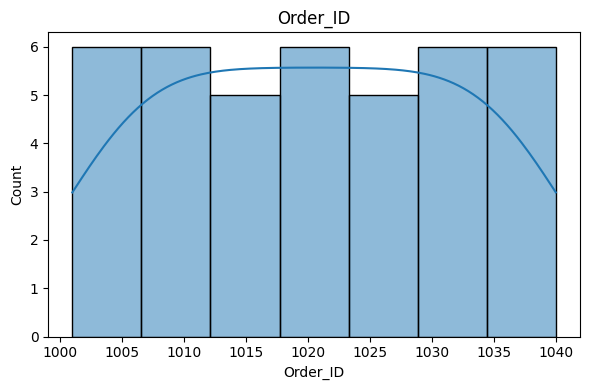

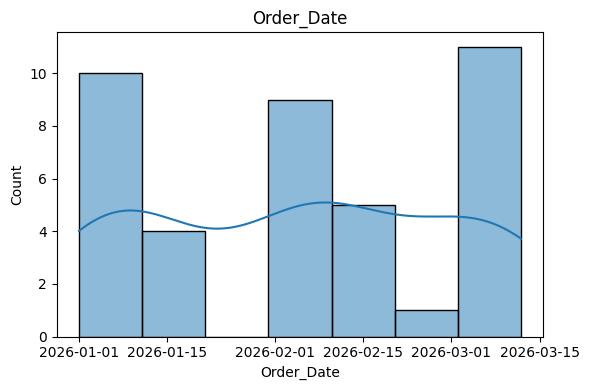

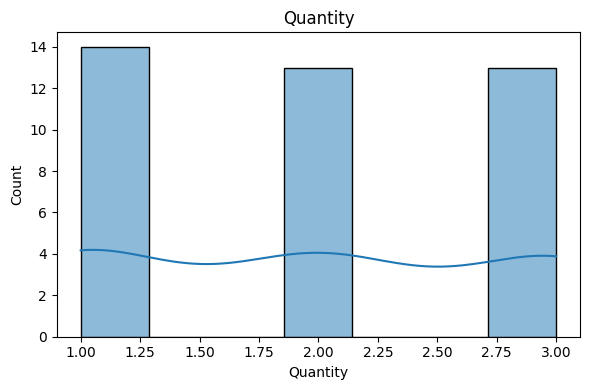

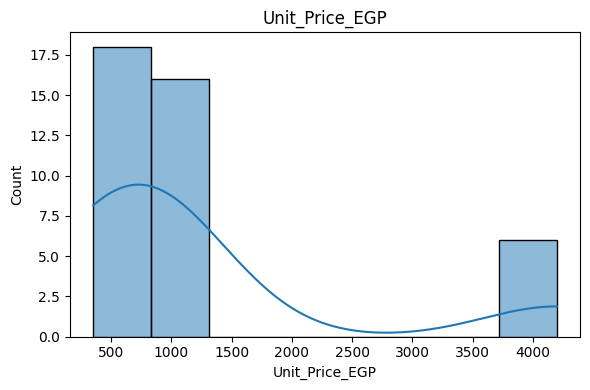

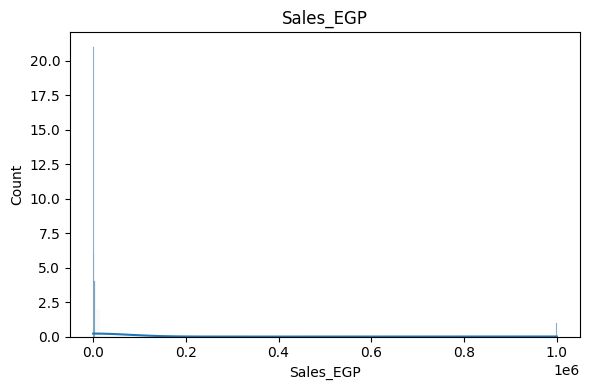

In [20]:
for col in num_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.tight_layout()
    plt.show()

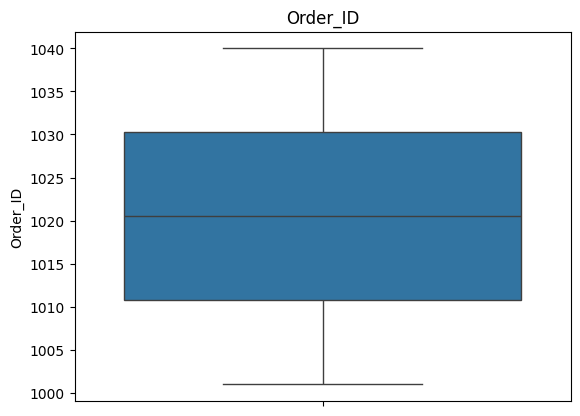

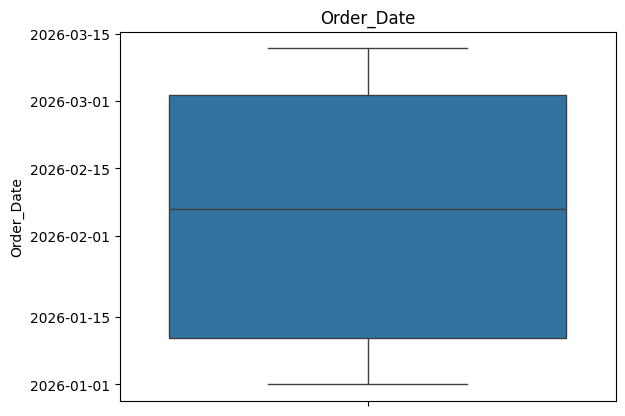

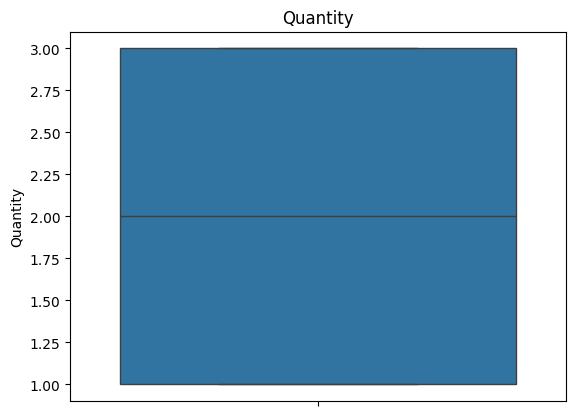

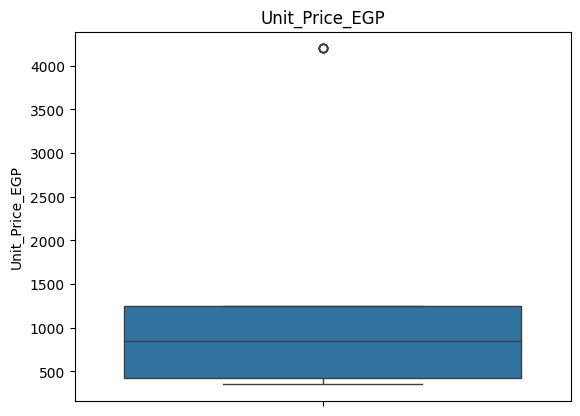

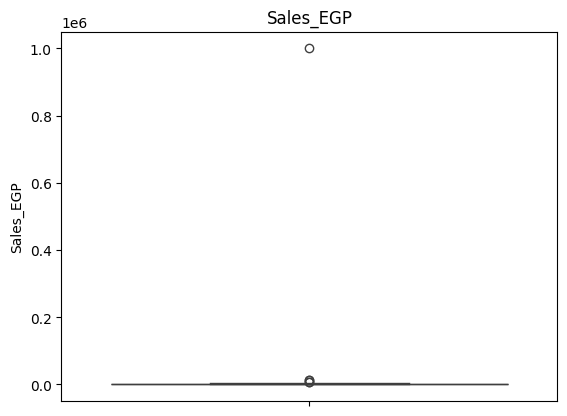

In [21]:
for i in num_columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

In [22]:
corr_matrix = df[num_columns].corr()

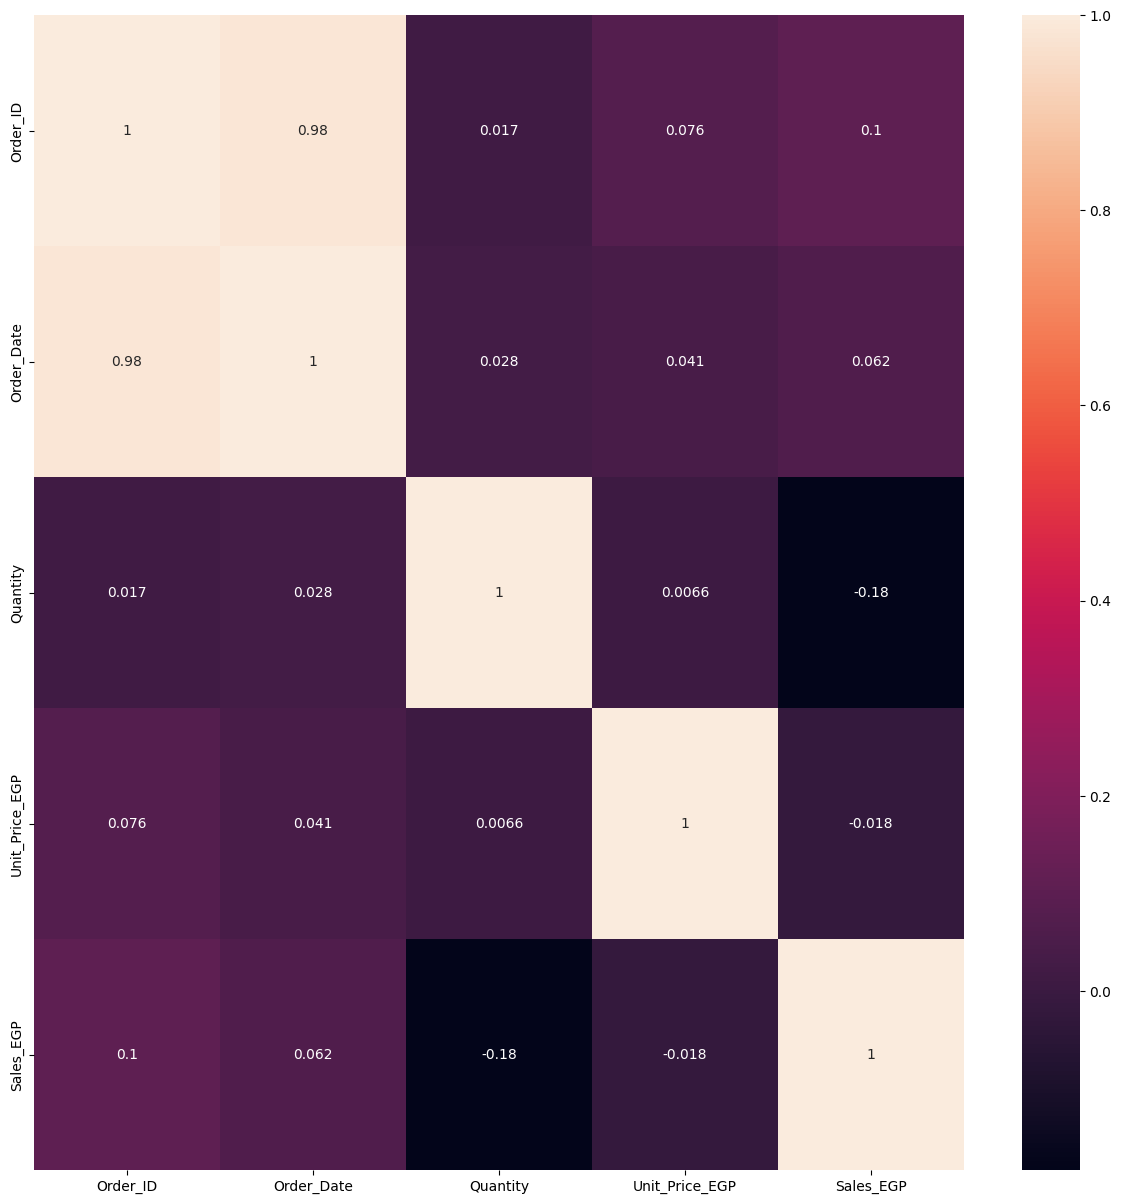

In [23]:
plt.figure(figsize=(15,15))
sns.heatmap(corr_matrix,annot=True)
plt.show()

Detect Outliers

In [24]:
numeric_cols = ["Quantity", "Unit_Price_EGP", "Sales_EGP"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

Quantity: 0 outliers
Unit_Price_EGP: 6 outliers
Sales_EGP: 5 outliers


 Analyze sales by category

In [25]:
print(df["Category"].unique())

['Accessories' 'Electronics']


In [26]:
category_sales = (
    df.groupby("Category")["Sales_EGP"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Electronics    1071589
Accessories      26870
Name: Sales_EGP, dtype: int64


In [27]:
category_percentage = (
    df.groupby("Category")["Sales_EGP"]
    .sum()
    / df["Sales_EGP"].sum()
    * 100
).sort_values(ascending=False)

print(category_percentage)

Category
Electronics    97.553846
Accessories     2.446154
Name: Sales_EGP, dtype: float64


In [28]:
category_analysis = (
    df.groupby("Category")["Sales_EGP"]
    .agg(Total_Sales="sum", Number_of_Orders="count")
    .sort_values("Total_Sales", ascending=False)
)

category_analysis["Sales_Percentage"] = (
    category_analysis["Total_Sales"]
    / category_analysis["Total_Sales"].sum()
    * 100
)

print(category_analysis)

             Total_Sales  Number_of_Orders  Sales_Percentage
Category                                                    
Electronics      1071589                17         97.553846
Accessories        26870                23          2.446154


In [29]:
top_category = category_analysis["Total_Sales"].idxmax()

print("Top Category:", top_category)

Top Category: Electronics


 Encode Category

In [30]:
df = pd.get_dummies(
    df,
    columns=["Category"],
    prefix="Category",
    dtype=int
)

 Encode City

In [31]:
df = pd.get_dummies(
    df,
    columns=["City"],
    prefix="City",
    dtype=int
)

Feature Engineering

In [32]:
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Day"] = df["Order_Date"].dt.day
df["DayOfWeek"] = df["Order_Date"].dt.dayofweek

df["Is_Weekend"] = df["DayOfWeek"].isin([5, 6]).astype(int)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40 entries, 0 to 39
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Order_ID              40 non-null     int64         
 1   Order_Date            40 non-null     datetime64[ns]
 2   Product               40 non-null     object        
 3   Quantity              40 non-null     float64       
 4   Unit_Price_EGP        40 non-null     float64       
 5   Sales_EGP             40 non-null     int64         
 6   Category_Accessories  40 non-null     int64         
 7   Category_Electronics  40 non-null     int64         
 8   City_Alexandria       40 non-null     int64         
 9   City_Cairo            40 non-null     int64         
 10  City_Giza             40 non-null     int64         
 11  Year                  40 non-null     int32         
 12  Month                 40 non-null     int32         
 13  Day                   40 no

Replace the Incorrect Value

In [34]:
import numpy as np

df["Sales_EGP"] = df["Sales_EGP"].replace(999999, np.nan)

In [35]:
df[df["Order_ID"] == 27]

,Order_ID,Order_Date,Product,Quantity,Unit_Price_EGP,Sales_EGP,Category_Accessories,Category_Electronics,City_Alexandria,City_Cairo,City_Giza,Year,Month,Day,DayOfWeek,Is_Weekend


In [36]:
df["Sales_EGP"] = df["Sales_EGP"].fillna(
    df["Quantity"] * df["Unit_Price_EGP"]
)

In [37]:
df[df["Order_ID"] == 27]

,Order_ID,Order_Date,Product,Quantity,Unit_Price_EGP,Sales_EGP,Category_Accessories,Category_Electronics,City_Alexandria,City_Cairo,City_Giza,Year,Month,Day,DayOfWeek,Is_Weekend


Prepare ML Features

In [38]:
X = df.drop(columns=["Sales_EGP"])
y = df["Sales_EGP"]

In [39]:
X = X.drop(columns=["Order_ID", "Product"], errors="ignore")

In [40]:
X.head()

,Order_Date,Quantity,Unit_Price_EGP,Category_Accessories,Category_Electronics,City_Alexandria,City_Cairo,City_Giza,Year,Month,Day,DayOfWeek,Is_Weekend
0,2026-01-01,1.0,350.0,1,0,0,1,0,2026,1,1,3,0
1,2026-01-02,2.0,850.0,1,0,0,0,1,2026,1,2,4,0
2,2026-01-03,3.0,420.0,1,0,1,0,0,2026,1,3,5,1
3,2026-01-04,1.0,690.0,1,0,0,1,0,2026,1,4,6,1
4,2026-01-05,2.0,4200.0,0,1,0,0,1,2026,1,5,0,0


In [41]:
y.head()

,Sales_EGP
0,350.0
1,1700.0
2,1260.0
3,690.0
4,8400.0


Final Check

In [42]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (40, 16)

Missing values:
Order_ID                0
Order_Date              0
Product                 0
Quantity                0
Unit_Price_EGP          0
Sales_EGP               0
Category_Accessories    0
Category_Electronics    0
City_Alexandria         0
City_Cairo              0
City_Giza               0
Year                    0
Month                   0
Day                     0
DayOfWeek               0
Is_Weekend              0
dtype: int64

Duplicate rows: 0

Features shape: (40, 13)
Target shape: (40,)


In [47]:
df.to_csv("/content/مبيعات متجر إلكتروني.csv", index=False)

In [48]:
import os

os.path.exists("/content/مبيعات متجر إلكتروني.csv")

True

## E-Commerce Sales Data Cleaning Summary

* Loaded and explored the dataset.
* Removed duplicate records.
* Handled missing values.
* Converted `Order_Date` to datetime format.
* Cleaned and standardized text features.
* Detected and reviewed outliers.
* Corrected an invalid `Sales_EGP` value using `Quantity × Unit_Price_EGP`.
* Analyzed sales by category.
* Applied One-Hot Encoding to `Category` and `City`.
* Prepared the cleaned dataset for Machine Learning.
